# Check area-weighted bin mean

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import etunc.config as cfg

In [15]:
PROC_ROOT = cfg.PROC_ROOT
FAMILY = "cmip"
BIN_VARIABLE = "et_clim"
TIME_PERIOD = "199501-201412"
NBINS = "lai15_ai15"
TAG = f"area_weighted.qbin_pooled_all"

In [17]:
p = PROC_ROOT / FAMILY / "qbin" / TIME_PERIOD / NBINS

f = f"{FAMILY}.{BIN_VARIABLE}.{TAG}.{NBINS}.1deg.{TIME_PERIOD}.nc"
ds1 = xr.open_dataset(p / f)

f = f"{FAMILY}.{BIN_VARIABLE}.{TAG}.{NBINS}.1deg.{TIME_PERIOD}.sources_pooled.nc"
ds2 = xr.open_dataset(p / f)

In [26]:
ds1

<xarray.Dataset> Size: 566kB
Dimensions:       (member: 44, stats: 7, y_bin: 15, x_bin: 15)
Coordinates: (12/16)
  * member        (member) <U25 4kB 'ACCESS-ESM1-5.r1i1p1f1' ... 'UKESM1-0-LL...
    member_id     (member) <U10 2kB ...
    source        (member) <U16 3kB 'ACCESS-ESM1-5' ... 'UKESM1-0-LL'
  * stats         (stats) <U9 252B 'mean' 'var_pop' ... 'sum_w' 'n_eff'
  * y_bin         (y_bin) int64 120B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14
    y_bin_lower   (y_bin) float64 120B ...
    ...            ...
    x_bin_lower   (x_bin) float64 120B ...
    x_bin_upper   (x_bin) float64 120B ...
    x_bin_center  (x_bin) float64 120B ...
    x_bin_label   (x_bin) <U8 480B ...
    ltype         int64 8B ...
    landunit      <U40 160B ...
Data variables:
    et            (member, stats, y_bin, x_bin) float64 554kB ...

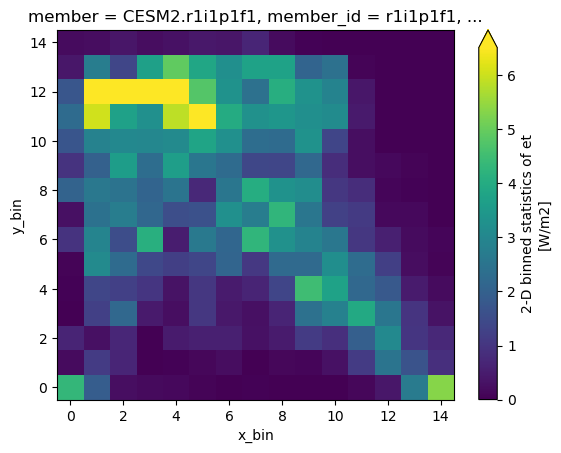

In [29]:
(ds1.et.sel(stats="count", source="CESM2") - ds1.et.sel(stats="n_eff", source="CESM2")).plot(robust=True)

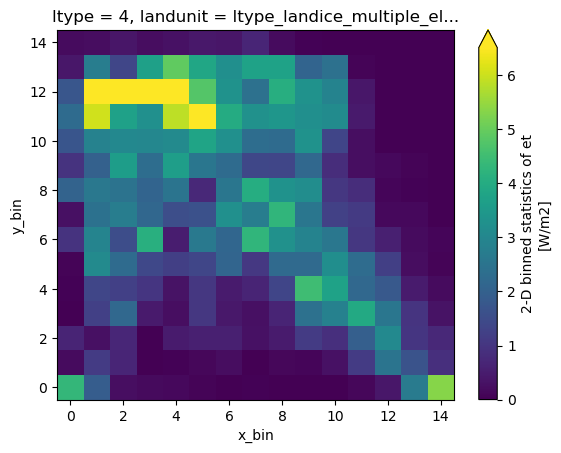

In [ ]:
(ds2.et.sel(stats="count", source="CESM2") - ds2.et.sel(stats="n_eff", source="CESM2")).plot(robust=True)

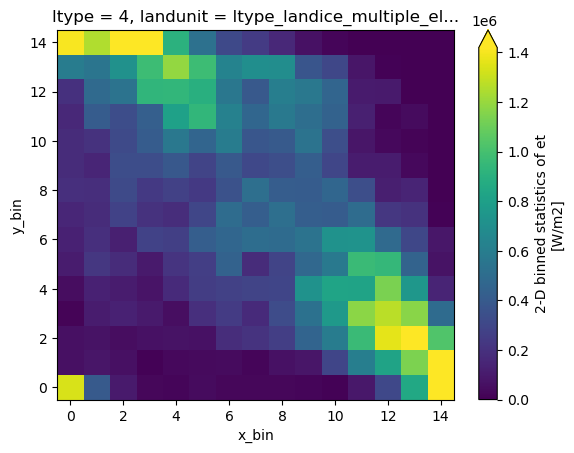

In [35]:
ds2.et.sel(stats="sum_w", source="CESM2").plot(robust=True)